# Коллекции
### От строк к структурам данных


# 1. Приведение типов. Строки
## Коллекции в Python

Коллекции — это способ хранить **несколько значений** в одной переменной. В разработке и аналитике они встречаются постоянно.

В этом ноутбуке разберём основные типы коллекций Python и научимся выбирать подходящий инструмент для задачи.

Python предлагает несколько встроенных типов для хранения наборов данных. У каждого — свои свойства: можно ли менять содержимое, сохраняется ли порядок, допускаются ли дубликаты.

| Тип | Изменяемый | Упорядоченный | Дубликаты | Типичное применение |
|-----|-----------|---------------|-----------|---------------------|
| `str` | Нет | Да | Да | Текст, названия |
| `list` | Да | Да | Да | Рейтинги, списки фильмов |
| `tuple` | Нет | Да | Да | Записи, координаты |
| `dict` | Да | Да* | Ключи: нет | Метаданные фильма |
| `set` | Да | Нет | Нет | Уникальные жанры |

*В Python 3.7+ словари сохраняют порядок вставки ключей.

**Как выбирать:**
- нужен список с возможностью добавлять новые → `list`;
- нужны уникальные значения без повторов → `set`;
- нужны пары «ключ → значение» → `dict`;
- нужна фиксированная запись, которую нельзя случайно изменить → `tuple`.

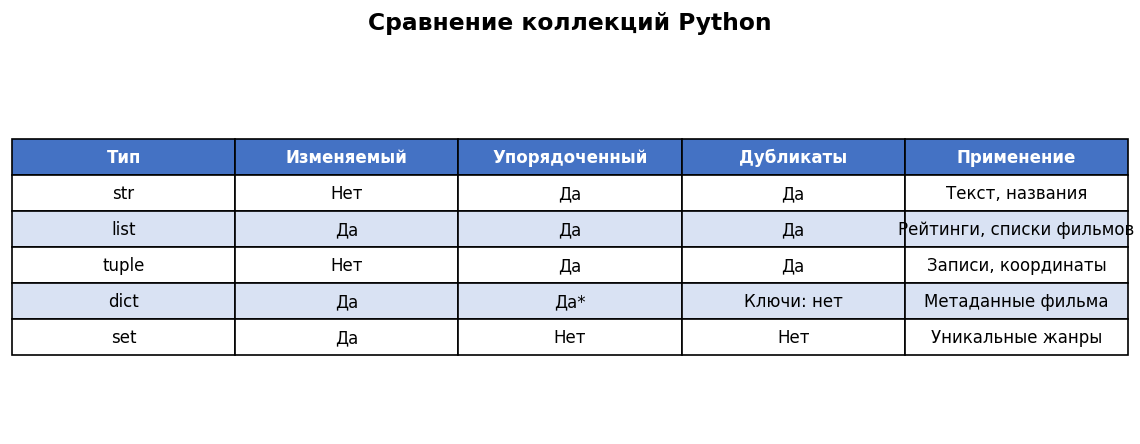

Дальше разберём каждый тип подробнее — от простых строк до словарей и множеств.



---


## Приведение типов

Данные часто приходят в виде текста — из файла, API или ввода пользователя. Перед обработкой их нужно преобразовать в определённый тип.

Строку можно превратить в число:

In [2]:
number = "123"

int(number)

123

Целое число — в дробное:

In [3]:
price = 19

float(price)

19.0

Число можно превратить в строку, а результат сравнения — в логическое значение:

In [4]:
year = 2010
rating = 8.8

str(year), bool(rating > 8.0)

('2010', True)

Пример из мира фильмов — год выпуска приходит как текст из CSV:

In [5]:
year_text = "1999"
year = int(year_text)
year

1999

Не все преобразования возможны. Если строка не является числом, Python выбросит ошибку:

In [6]:
# int("abc")  # ValueError: invalid literal for int()



---


## Строки

Строка (`str`) — это последовательность символов.

Строки **неизменяемы**: нельзя заменить отдельный символ, можно только создать новую строку.

In [7]:
text = "Python"
text

'Python'

### Индексация

Каждый символ имеет индекс. Отрицательные индексы считаются с конца.

In [8]:
text = "Python"

text[0], text[1], text[-1]

('P', 'y', 'n')

### Срезы

Срез `text[start:stop]` возвращает подстроку от `start` до `stop` (не включая `stop`).

In [9]:
text = "Python"

text[0:3]

'Pyt'

In [10]:
text[:4]

'Pyth'

In [11]:
text[2:]

'thon'

### Полезные методы строк

Строки имеют встроенные методы для обработки текста.

In [12]:
title = "  INCEPTION  "

title.strip().lower()

'inception'

Метод `.split()` разбивает строку по разделителю — удобно для парсинга жанров:

In [13]:
genres_string = "Drama|Action|Comedy"
genres_string.split("|")

['Drama', 'Action', 'Comedy']

Метод `.join()` собирает список обратно в строку:

In [14]:
genres = ["Drama", "Action", "Comedy"]
" / ".join(genres)

'Drama / Action / Comedy'

f-строки позволяют вставлять переменные прямо в текст:

In [15]:
movie = "Inception"
year = 2010
rating = 8.8

f"{movie} ({year}) — рейтинг {rating}"

'Inception (2010) — рейтинг 8.8'

Попытка изменить символ строки вызовет ошибку — строка неизменяема:

In [16]:
# text[0] = "p"  # TypeError: str does not support item assignment

### Проход по строке циклом

In [17]:
for char in "Python":
    print(char)

P
y
t
h
o
n




---


# 2. Списки и list comprehension

## Списки
Список (`list`) — упорядоченная **изменяемая** коллекция. Это самый универсальный контейнер в Python.

In [18]:
movies = ["Interstellar", "Inception", "Matrix"]
movies

['Interstellar', 'Inception', 'Matrix']

### Индексация списка

In [19]:
movies[0]

'Interstellar'

In [20]:
movies[-1]

'Matrix'

### Срезы списка

Срезы работают так же, как у строк. Можно задать шаг:

In [21]:
movies[:2]

['Interstellar', 'Inception']

In [22]:
movies[::2]  # Каждый второй элемент

['Interstellar', 'Matrix']

## Основные операции со списками

In [23]:
movies.append("Avatar")
movies

['Interstellar', 'Inception', 'Matrix', 'Avatar']

In [24]:
movies.remove("Avatar")
movies

['Interstellar', 'Inception', 'Matrix']

Другие полезные методы:

In [25]:
movies.insert(1, "Blade Runner")
movies

['Interstellar', 'Blade Runner', 'Inception', 'Matrix']

In [26]:
last = movies.pop()
last, movies

('Matrix', ['Interstellar', 'Blade Runner', 'Inception'])

In [27]:
more = ["Dune", "Arrival"]
movies.extend(more)
movies

['Interstellar', 'Blade Runner', 'Inception', 'Dune', 'Arrival']

In [28]:
len(movies)

5

Сортировка — `sort()` меняет список на месте, `sorted()` возвращает новый:

In [29]:
ratings = [5, 4, 5, 3, 4]
sorted(ratings, reverse=True)

[5, 5, 4, 4, 3]

### Вложенные списки

Список может содержать другие списки — например, матрица оценок:

In [30]:
ratings_matrix = [[5, 4, 5], [3, 4, 5], [5, 5, 4]]
ratings_matrix[0][1]

4

### Проход по списку циклом

In [31]:
for movie in movies:
    print(movie)

Interstellar
Blade Runner
Inception
Dune
Arrival


### Распаковка

Удобный способ разложить элементы коллекции по переменным.

In [32]:
first, second, third = movies[:3]

first, second, third

('Interstellar', 'Blade Runner', 'Inception')



---


## List comprehension

**List comprehension** — компактный способ создать список из другой коллекции. Читается практически как обычное предложение.

Синтаксис: `[выражение for элемент in коллекция]`

Базовый пример — удвоить каждый элемент:

In [33]:
ratings = [5, 4, 5, 3, 4]
doubled = [r * 2 for r in ratings]
doubled

[10, 8, 10, 6, 8]

С условием — оставить только высокие оценки:

In [34]:
high_ratings = [r for r in ratings if r >= 4]
high_ratings

[5, 4, 5, 4]

Вложенный comprehension — разобрать жанры из нескольких строк:

In [35]:
genre_lines = ["Drama|Action", "Comedy|Drama", "Sci-Fi|Action"]

all_genres = [genre for line in genre_lines for genre in line.split("|")]
all_genres

['Drama', 'Action', 'Comedy', 'Drama', 'Sci-Fi', 'Action']

Тот же результат через обычный цикл — для сравнения:

In [36]:
all_genres_loop = []
for line in genre_lines:
    for genre in line.split("|"):
        all_genres_loop.append(genre)
all_genres_loop

['Drama', 'Action', 'Comedy', 'Drama', 'Sci-Fi', 'Action']

Comprehension уместен, когда нужно **создать новый список** в одну строку. Для сложной логики лучше использовать обычный цикл — читаемость важнее краткости.



---


# 3. Кортежи и множества
## Кортежи

Кортеж (`tuple`) похож на список, но **неизменяем**. После создания нельзя добавить, удалить или заменить элемент.

**Зачем нужны кортежи:**
- фиксированные записи;
- можно использовать как ключ словаря (списки — нельзя);
- функции часто возвращают несколько значений именно кортежем.

In [37]:
coordinates = (10, 20)
coordinates

(10, 20)

Кортеж из одного элемента требует запятую:

In [38]:
single = (42,)
type(single)

tuple

### Распаковка кортежа

In [39]:
movie = ("Inception", 2010, 8.8)
title, year, rating = movie

title, year, rating

('Inception', 2010, 8.8)

Распаковка с `*` — собрать «середину» в список:

In [40]:
data = (1, 2, 3, 4, 5)
first, *middle, last = data

first, middle, last

(1, [2, 3, 4], 5)

### Кортеж как ключ словаря

Кортежи хешируемы, поэтому могут быть ключами:

In [41]:
movie_ratings = {
    (2010, "Inception"): 8.8,
    (1999, "Matrix"): 8.7,
}

movie_ratings[(1999, "Matrix")]

8.7

Попытка изменить кортеж вызовет ошибку:

In [42]:
# coordinates[0] = 5  # TypeError: tuple does not support item assignment

### Named tuple

Для удобства можно дать имена полям кортежа:

In [43]:
from collections import namedtuple

Movie = namedtuple("Movie", ["title", "year", "rating"])
inception = Movie("Inception", 2010, 8.8)

inception.title, inception.rating

('Inception', 8.8)



---


## Множества

Множество (`set`) хранит только **уникальные** элементы. Порядок элементов не гарантируется.

In [44]:
genres = {"Drama", "Action", "Drama", "Comedy"}
genres

{'Action', 'Comedy', 'Drama'}

Дубликаты автоматически удаляются. Множество можно создать из списка:

In [45]:
genres_list = ["Drama", "Action", "Drama", "Comedy"]
set(genres_list)

{'Action', 'Comedy', 'Drama'}

### Проверка принадлежности

In [46]:
"Drama" in genres

True

### Операции с множествами

In [47]:
genres.add("Sci-Fi")
genres.discard("Comedy")
genres

{'Action', 'Drama', 'Sci-Fi'}

### Множественная алгебра

Операции над жанрами двух пользователей:

In [48]:
user_a = {"Drama", "Sci-Fi", "Action"}
user_b = {"Drama", "Comedy", "Action"}

print("Общие:", user_a & user_b)
print("Все:", user_a | user_b)
print("Только A:", user_a - user_b)
print("Только один из:", user_a ^ user_b)

Общие: {'Drama', 'Action'}
Все: {'Comedy', 'Drama', 'Sci-Fi', 'Action'}
Только A: {'Sci-Fi'}
Только один из: {'Comedy', 'Sci-Fi'}


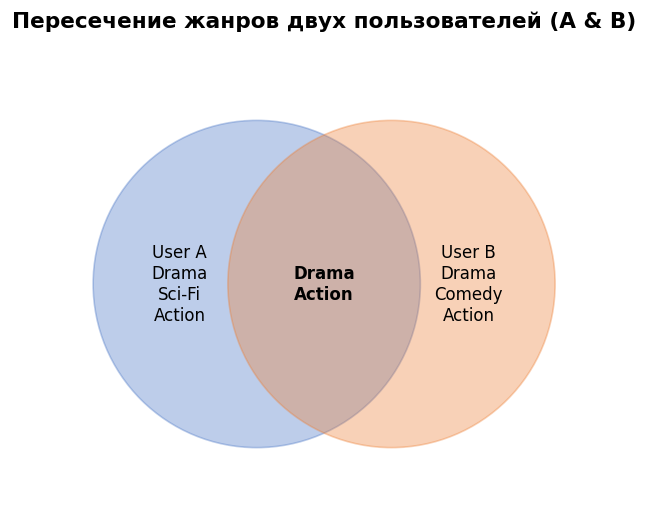

### frozenset — неизменяемое множество

Можно использовать как ключ словаря (обычный `set` — нельзя):

In [49]:
frozen = frozenset(["Drama", "Action"])
genre_groups = {frozen: "group_1"}
genre_groups

{frozenset({'Action', 'Drama'}): 'group_1'}



---


# 4. Словари и dict comprehension. Память, ссылки и изменяемость
## Словари

Словарь (`dict`) хранит пары **ключ → значение**. По ключу можно быстро получить значение — это основная структура для метаданных.

**Ключи** должны быть неизменяемыми (`str`, `int`, `tuple`). **Значения** могут быть любыми — числами, списками, другими словарями.

In [50]:
movie = {
    "title": "Inception",
    "year": 2010,
    "genres": ["Sci-Fi", "Action"],
    "rating": 8.8,
}
movie

{'title': 'Inception',
 'year': 2010,
 'genres': ['Sci-Fi', 'Action'],
 'rating': 8.8}

### Доступ к значениям

In [51]:
movie["title"]

'Inception'

Метод `.get()` безопаснее — возвращает значение по умолчанию, если ключ не найден:

In [52]:
movie.get("director", "Unknown")

'Unknown'

### Изменение и добавление

In [53]:
movie["director"] = "Nolan"
movie["rating"] = 9.0
movie

{'title': 'Inception',
 'year': 2010,
 'genres': ['Sci-Fi', 'Action'],
 'rating': 9.0,
 'director': 'Nolan'}

### Просмотр ключей, значений и пар

In [54]:
list(movie.keys())

['title', 'year', 'genres', 'rating', 'director']

In [55]:
list(movie.values())

['Inception', 2010, ['Sci-Fi', 'Action'], 9.0, 'Nolan']

In [56]:
list(movie.items())

[('title', 'Inception'),
 ('year', 2010),
 ('genres', ['Sci-Fi', 'Action']),
 ('rating', 9.0),
 ('director', 'Nolan')]

### Перебор словаря

In [57]:
for key, value in movie.items():
    print(f"{key}: {value}")

title: Inception
year: 2010
genres: ['Sci-Fi', 'Action']
rating: 9.0
director: Nolan


### Создание словаря из пар

Функция `zip()` объединяет несколько списков в пары:

In [58]:
titles = ["Inception", "Matrix", "Avatar"]
years = [2010, 1999, 2009]

dict(zip(titles, years))

{'Inception': 2010, 'Matrix': 1999, 'Avatar': 2009}



---


## Dict comprehension

Аналог list comprehension для словарей.

Синтаксис: `{ключ: значение for элемент in коллекция}`

In [59]:
ratings = {"Inception": 8.8, "Matrix": 8.7, "Avatar": 7.8}

high_rated = {title: rating for title, rating in ratings.items() if rating >= 8.0}
high_rated

{'Inception': 8.8, 'Matrix': 8.7}

Можно создать словарь из списка с нумерацией:

In [60]:
movies = ["Inception", "Matrix", "Avatar"]
indexed = {i: movie for i, movie in enumerate(movies)}
indexed

{0: 'Inception', 1: 'Matrix', 2: 'Avatar'}



---


Теперь, когда мы познакомились со всеми основными коллекциями, можно глубже разобрать **изменяемость** и то, как объекты хранятся в памяти.

Это объясняет поведение, которое мы уже видели на практике:
- почему `append` меняет список «на месте»,
- почему кортеж нельзя изменить,
- почему строка при «изменении» создаёт новый объект.

## Память, ссылки и изменяемость

В Python переменная — это **имя (ссылка)**, которое указывает на объект в памяти.

```text
name ───► объект в памяти
```

Коллекции делятся на два класса:

- **Неизменяемые (immutable):** `str`, `tuple`, `frozenset` — нельзя изменить «на месте», при «изменении» создаётся новый объект.
- **Изменяемые (mutable):** `list`, `dict`, `set` — содержимое можно менять, объект в памяти остаётся тем же.

Это важно понимать при передаче данных в функции и при создании копий.

### Неизменяемая строка

Когда мы «меняем» строку, Python создаёт **новый** объект и перенаправляет имя.

In [61]:
text = "Python"
print("До:", text, "| id:", id(text))

text = text + "!"
print("После:", text, "| id:", id(text))

До: Python | id: 139634238787280
После: Python! | id: 139633900814432


Идентификаторы (`id`) разные — это два разных объекта в памяти.

### Изменяемый список

Список можно менять «на месте» — идентификатор объекта при этом **не меняется**.

In [62]:
movies = ["Matrix", "Inception"]
print("До:", movies, "| id:", id(movies))

movies.append("Interstellar")
print("После:", movies, "| id:", id(movies))

До: ['Matrix', 'Inception'] | id: 139633900799232
После: ['Matrix', 'Inception', 'Interstellar'] | id: 139633900799232


### Алиасы: две переменные — один объект

Если присвоить переменную другой переменной, обе будут ссылаться на **один и тот же** объект.

In [63]:
watchlist = ["Matrix", "Inception"]
backup = watchlist

backup.append("Interstellar")

print("watchlist:", watchlist)
print("backup:", backup)
print("Один объект?", id(watchlist) == id(backup))

watchlist: ['Matrix', 'Inception', 'Interstellar']
backup: ['Matrix', 'Inception', 'Interstellar']
Один объект? True


Обе переменные указывают на один список — изменение через `backup` затрагивает и `watchlist`.

### Копирование списка

Чтобы получить независимую копию, используйте `.copy()` или `list()`.

In [64]:
original = ["Matrix", "Inception"]
copy = original.copy()

copy.append("Avatar")

print("original:", original)
print("copy:", copy)

original: ['Matrix', 'Inception']
copy: ['Matrix', 'Inception', 'Avatar']


### Кортеж с изменяемым элементом внутри

Кортеж сам по себе неизменяем, но внутри него могут лежать изменяемые объекты — например, список.

In [65]:
record = ("Inception", 2010, [8.8, 9.0])
record[2].append(8.5)

print(record)

('Inception', 2010, [8.8, 9.0, 8.5])


Изменить сам кортеж (`record[0] = ...`) нельзя, но список внутри — можно.

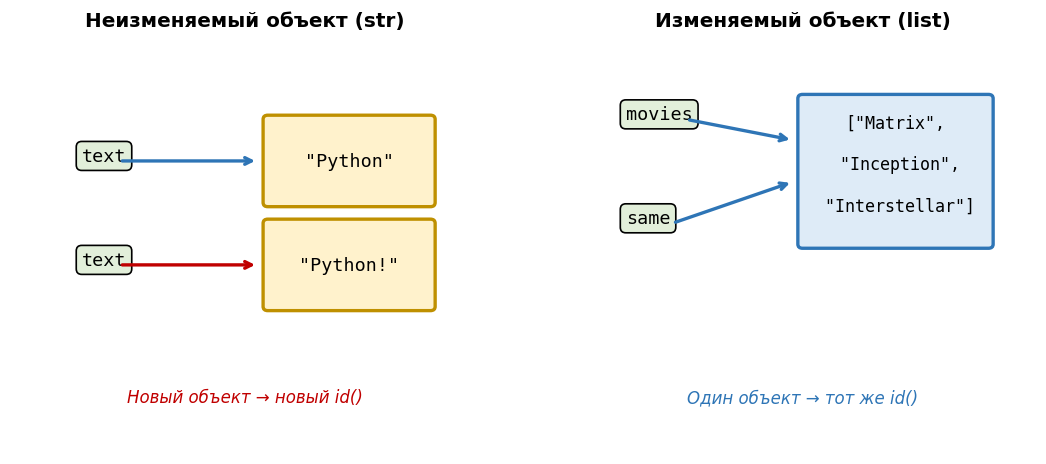

Функция `id()` показывает уникальный идентификатор объекта в памяти. Сейчас не нужно запоминать числа — важно понять **идею**: переменная указывает на объект, а изменяемость определяет, создаётся ли новый объект при «изменении».



---


## Интересные фишки Python

Несколько полезных инструментов, которые часто используют вместе с коллекциями.

### enumerate — индекс и значение одновременно

In [66]:
for i, movie in enumerate(movies):
    print(f"{i + 1}. {movie}")

1. Matrix
2. Inception
3. Interstellar


### zip — объединение нескольких коллекций

In [67]:
titles = ["Inception", "Matrix"]
years = [2010, 1999]

list(zip(titles, years))

[('Inception', 2010), ('Matrix', 1999)]

### any и all — проверка условий

In [68]:
ratings = [5, 4, 5, 3, 4]

any(r >= 5 for r in ratings), all(r >= 3 for r in ratings)

(True, True)

### sorted с key — сортировка по правилу

In [69]:
sorted(movies, key=len)

['Matrix', 'Inception', 'Interstellar']

### Распаковка списков через `*`

In [70]:
favorites = ["Inception", "Matrix"]
watchlist = ["Avatar", "Dune"]

combined = [*favorites, *watchlist]
combined

['Inception', 'Matrix', 'Avatar', 'Dune']

### Counter — подсчёт элементов

In [71]:
from collections import Counter

genre_list = ["Drama", "Action", "Drama", "Comedy", "Drama", "Action"]
Counter(genre_list)

Counter({'Drama': 3, 'Action': 2, 'Comedy': 1})

### defaultdict — словарь со значением по умолчанию

In [72]:
from collections import defaultdict

movies_by_genre = defaultdict(list)
movies_by_genre["Drama"].append("Inception")
movies_by_genre["Action"].append("Matrix")

dict(movies_by_genre)

{'Drama': ['Inception'], 'Action': ['Matrix']}



---


## Практика на данных о фильмах

Соберём мини-аналитику, используя только коллекции Python.

### Средний рейтинг из списка

In [79]:
ratings = [5, 4, 5, 3, 4]

average = sum(ratings) / len(ratings)
average

4.2

### Уникальные жанры из строки

In [80]:
genres_raw = "Drama|Action|Drama|Comedy|Action"
unique_genres = {genre for genre in genres_raw.split("|")}
unique_genres

{'Action', 'Comedy', 'Drama'}

### Фильтрация словаря рейтингов

In [82]:
movie_ratings = {
    "Inception": 8.8,
    "Matrix": 8.7,
    "Avatar": 7.8,
    "Dune": 8.5,
    "Tenet": 7.4,
}

top_movies = [k for k, v in movie_ratings.items() if v >= 8.0]
top_movies

['Inception', 'Matrix', 'Dune']

### Записи фильмов как кортежи

In [83]:
films = [
    ("Inception", 2010, 8.8),
    ("Matrix", 1999, 8.7),
    ("Avatar", 2009, 7.8),
]

recent = [f for f in films if f[1] > 2000]
recent

[('Inception', 2010, 8.8), ('Avatar', 2009, 7.8)]

### Итоговая мини-аналитика

In [86]:
from collections import Counter

all_ratings = [5, 4, 5, 3, 4, 5, 2, 4]
all_genres = ["Drama", "Action", "Drama", "Sci-Fi", "Action", "Drama"]

summary = Counter(zip(all_genres, all_ratings))

summary

Counter({('Drama', 5): 3, ('Action', 4): 2, ('Sci-Fi', 3): 1})